# Fall classifier on FallAllD (wrist device D2)

**What we are building:** a model that looks at a short slice of wrist motion (2.5 seconds) and answers **fall** or **not fall**.

**Supervised learning in one paragraph:** every example has a *label* (the right answer). The model sees many labelled examples (the *training set*), learns the pattern, and is then tested on examples it has never seen (the *test set*). If the test score is good, it learned something real and not just memorised.

**The 6 steps:** 1. load + convert, 2. cut into windows + label, 3. split by person, 4. turn windows into numbers (features), 5. train models, 6. judge with the right scores.

In [1]:
from pathlib import Path
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix

pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

FAD_ROOT = Path('../../data/open datasets/FallAllD__zip/FallAllD')
FS_IN, FS_OUT = 238, 50          # original rate -> SilverGuard rate
ACC_COUNTS_PER_G = 4096          # checked in the audit notebook: resting |a| = ~4,061 counts
WIN, HOP = 125, 62               # 2.5 s windows, ~50% overlap (same idea as context.md)
WRIST_DEVICE = 2                 # believed to be the wrist - checked below, still unconfirmed
SEED = 42

## Step 1. Load and convert (device D2 only)

Three things must be done to the raw files:
1. **Accelerometer counts -> g** (divide by 4096), so 1.0 means "normal gravity".
2. **238 Hz -> 50 Hz.** Our real sensor gives 50 readings per second, so we train on 50 Hz. `resample_poly` also smooths the signal first so no fake patterns appear (this is called anti-aliasing).
3. Gyroscope scale is **not known** from the folder, so we keep it in raw counts. Tree models do not care, and for logistic regression we standardise every feature anyway.

First, a quick sanity check that D2 behaves like a wrist (wrists usually rotate the most during everyday movement). This is supporting evidence only, not proof.

In [2]:
def read_dat(p):
    return pd.read_csv(p, header=None, dtype='int16').to_numpy()

def gyro_path(p):
    return p.with_name(p.name[:-len('A.dat')] + 'G.dat')

# does D2 rotate more than D1 / D3 in everyday (ADL) recordings?
rng = np.random.default_rng(SEED)
rows = []
for dev in (1, 2, 3):
    files = [p for p in sorted(FAD_ROOT.glob(f'S??_D{dev}_A0??_T*_A.dat'))]    # A0xx = daily activities
    for p in rng.choice(files, 150, replace=False):
        g = read_dat(gyro_path(Path(p))).astype('float32')
        rows.append({'device': dev, 'gyro_motion': float(np.linalg.norm(g, axis=1).std())})
print(pd.DataFrame(rows).groupby('device').gyro_motion.median().to_frame('median gyro motion (counts)'))

        median gyro motion (counts)
device                             
1                           375.843
2                           676.518
3                           423.145


In [3]:
PAT = re.compile(r'^S(\d+)_D(\d)_A(\d+)_T(\d+)_A\.dat$')

def load_device(dev):
    meta, acc, gyr = [], [], []
    for p in sorted(FAD_ROOT.glob(f'S??_D{dev}_A???_T*_A.dat')):
        s, d, a, t = map(int, PAT.match(p.name).groups())
        A = resample_poly(read_dat(p).astype('float32') / ACC_COUNTS_PER_G, FS_OUT, FS_IN, axis=0)
        G = resample_poly(read_dat(gyro_path(p)).astype('float32'), FS_OUT, FS_IN, axis=0)
        meta.append({'subject': s, 'activity': a, 'trial': t, 'is_fall': a >= 100})
        acc.append(A.astype('float32')); gyr.append(G.astype('float32'))
    return pd.DataFrame(meta), np.stack(acc), np.stack(gyr)

t0 = time.time()
trials, ACC, GYR = load_device(WRIST_DEVICE)
print(f'loaded in {time.time()-t0:.0f}s | recordings: {len(trials)} | ACC shape {ACC.shape} (recordings, samples, xyz)')
print(trials.is_fall.value_counts().rename({True: 'fall', False: 'daily activity'}).to_dict(), '| subjects:', trials.subject.nunique())

loaded in 53s | recordings: 2515 | ACC shape (2515, 1000, 3) (recordings, samples, xyz)
{'daily activity': 1992, 'fall': 523} | subjects: 13


## Step 2. Cut into windows and label them (the most important step)

A model cannot read a whole 20 s recording at once, so we cut it into **2.5 s windows**, sliding forward about 1.2 s each time (windows overlap by half, so a fall is never split unluckily).

**Labels:** in a fall recording we find the **impact** (the biggest acceleration spike). A window containing the impact is **fall = 1**. Every other window is **not fall = 0**: the calm parts before/after a fall, and all windows from daily-activity recordings.

Why not label whole recordings? In FallAllD every fall is in the middle of the 20 s, so the model could cheat with "spike in the middle = fall". With windows, daily-activity spikes land anywhere, so the model has to learn what a fall really looks like.

In [4]:
starts = np.arange(0, ACC.shape[1] - WIN + 1, HOP)
mag_all = np.linalg.norm(ACC, axis=2)                    # (recordings, samples)
impact = mag_all.argmax(axis=1)                          # sample index of the biggest spike

def cut(arr):                                            # -> (recordings, windows, WIN, 3)
    return np.stack([arr[:, s:s + WIN] for s in starts], axis=1)

accW, gyrW = cut(ACC), cut(GYR)
has_impact = (impact[:, None] >= starts[None, :]) & (impact[:, None] < starts[None, :] + WIN)
yW = has_impact & trials.is_fall.to_numpy()[:, None]

n_rec, n_win = yW.shape
win_meta = pd.DataFrame({
    'rec': np.repeat(np.arange(n_rec), n_win),
    'subject': np.repeat(trials.subject.to_numpy(), n_win),
    'activity': np.repeat(trials.activity.to_numpy(), n_win),
    'start': np.tile(starts, n_rec),
    'y': yW.ravel().astype(int),
})
X_acc, X_gyr = accW.reshape(-1, WIN, 3), gyrW.reshape(-1, WIN, 3)
print(f'{len(win_meta):,} windows | fall windows: {win_meta.y.sum():,} ({win_meta.y.mean()*100:.1f}%) | not-fall: {(1-win_meta.y).sum():,}')
print('fall windows per fall recording:', win_meta[win_meta.activity >= 100].groupby('rec').y.sum().describe()[['mean', 'min', 'max']].round(2).to_dict())

37,725 windows | fall windows: 1,045 (2.8%) | not-fall: 36,680
fall windows per fall recording: {'mean': 2.0, 'min': 1.0, 'max': 3.0}


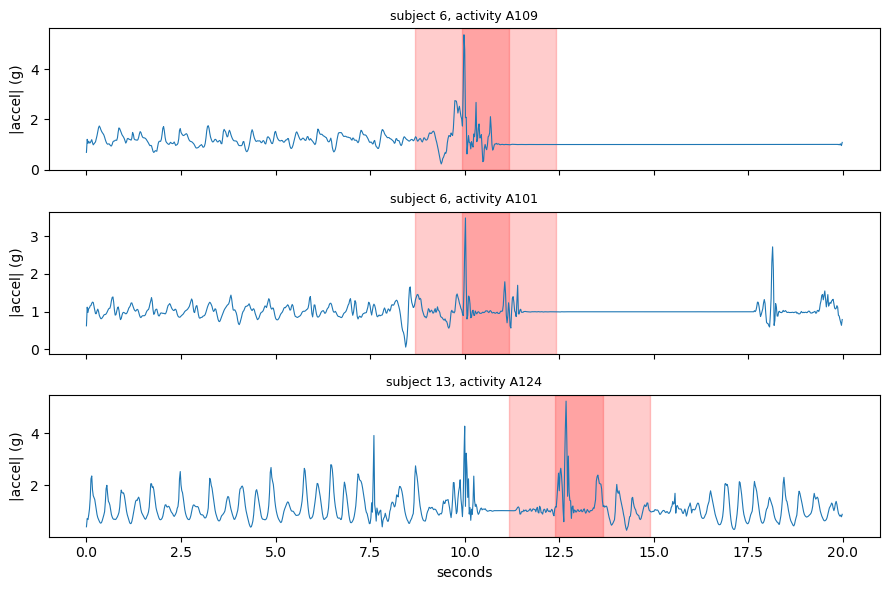

In [5]:
# Sanity check: do the labelled windows sit on the spike? (3 random fall recordings)
pick = np.random.default_rng(1).choice(np.where(trials.is_fall)[0], 3, replace=False)
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, r in zip(axes, pick):
    t = np.arange(ACC.shape[1]) / FS_OUT
    ax.plot(t, mag_all[r], lw=0.8)
    for s, lab in zip(starts, yW[r]):
        if lab: ax.axvspan(s / FS_OUT, (s + WIN) / FS_OUT, color='red', alpha=0.2)
    ax.set_ylabel('|accel| (g)'); ax.set_title(f'subject {trials.subject[r]}, activity A{trials.activity[r]}', fontsize=9)
axes[-1].set_xlabel('seconds'); plt.tight_layout(); plt.show()

## Step 3. Split by person, never at random

We hold out **3 people** as the final exam (*test set*). The model never sees them while we build it. Everything else is the *training set*.

Why by person? One person's windows look alike. If the same person is in both training and test, the model can recognise *the person* and the score looks great but is fake. This is called **leakage**. Real users are new people, so the test must contain new people.

In [6]:
subjects = np.sort(trials.subject.unique())
test_subjects = np.sort(np.random.default_rng(SEED).choice(subjects, 3, replace=False))
is_test = win_meta.subject.isin(test_subjects).to_numpy()
assert set(win_meta.subject[is_test]).isdisjoint(set(win_meta.subject[~is_test])), 'leakage: same person in train and test'
print('all subjects:', subjects.tolist()); print('test subjects:', test_subjects.tolist())
print(pd.DataFrame({'windows': [(~is_test).sum(), is_test.sum()], 'fall windows': [win_meta.y[~is_test].sum(), win_meta.y[is_test].sum()],
                    'people': [len(subjects) - 3, 3]}, index=['train', 'test']))

all subjects: [1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 13, 14, 15]
test subjects: [1, 11, 12]
       windows  fall windows  people
train    29415           899      10
test      8310           146       3


## Step 4. Features: turn each window into numbers

A model needs a row of numbers per window. For each of the 8 signals (accel x, y, z and overall size; gyro x, y, z and overall size) we compute **mean, std, min, max, range**. We add a few fall-specific ones:
- `am_jerk_max`: how *suddenly* the acceleration changes (impacts are abrupt),
- `am_energy`: how much movement overall,
- `am_tail_std`: movement in the last second (after a fall the person is usually still).

The overall size of the acceleration (`am`) is the same however the watch is rotated, which helps when the watch sits differently on different wrists.

In [7]:
def make_features(acc, gyr):
    am, gm = np.linalg.norm(acc, axis=2), np.linalg.norm(gyr, axis=2)
    sig = {'ax': acc[..., 0], 'ay': acc[..., 1], 'az': acc[..., 2], 'am': am,
           'gx': gyr[..., 0], 'gy': gyr[..., 1], 'gz': gyr[..., 2], 'gm': gm}
    f = {}
    for k, v in sig.items():
        f[f'{k}_mean'], f[f'{k}_std'] = v.mean(1), v.std(1)
        f[f'{k}_min'], f[f'{k}_max'] = v.min(1), v.max(1)
        f[f'{k}_range'] = v.max(1) - v.min(1)
    f['am_jerk_max'] = np.abs(np.diff(am, axis=1)).max(1) * FS_OUT
    f['am_energy'] = (am ** 2).mean(1)
    f['am_tail_std'] = am[:, -FS_OUT:].std(1)
    f['gm_jerk_max'] = np.abs(np.diff(gm, axis=1)).max(1) * FS_OUT
    return pd.DataFrame(f)

X = make_features(X_acc, X_gyr); y = win_meta.y.to_numpy(); groups = win_meta.subject.to_numpy()
Xtr, ytr, gtr = X[~is_test], y[~is_test], groups[~is_test]
Xte, yte = X[is_test], y[is_test]
print('feature table:', X.shape, '| missing values:', int(X.isna().sum().sum()))
X.head(3)

feature table: (37725, 44) | missing values: 0


,ax_mean,ax_std,ax_min,ax_max,ax_range,ay_mean,ay_std,ay_min,ay_max,ay_range,...,gz_range,gm_mean,gm_std,gm_min,gm_max,gm_range,am_jerk_max,am_energy,am_tail_std,gm_jerk_max
0,-0.167,0.007,-0.180,-0.101,0.078,0.152,0.007,0.093,0.169,0.076,...,23.305,40.209,6.846,19.123,61.588,42.465,23.699,0.987,0.002,"1,189.025"
1,-0.168,0.004,-0.177,-0.158,0.019,0.153,0.005,0.139,0.169,0.030,...,27.571,41.110,5.935,28.187,61.588,33.401,0.367,0.991,0.002,671.001
2,-0.167,0.004,-0.177,-0.158,0.019,0.153,0.004,0.145,0.169,0.024,...,28.680,40.048,5.428,24.732,55.443,30.711,0.367,0.990,0.002,573.911


## Step 5. Train models, simplest first

1. **Rule baseline** (no learning): "if the biggest acceleration in the window is over 2.5 g (or 3 g), call it a fall". This is the starting idea in `context.md`. A trained model is only worth it if it beats this.
2. **Logistic regression**: a simple, readable model.
3. **Random forest**: many small decision trees voting. Usually strong on this kind of table.

Falls are rare (a few % of windows), so we tell the models to pay extra attention to them (`class_weight`).

To compare models fairly *without touching the test people*, we use **grouped cross-validation** on the training people: train on some people, check on the others, rotate 5 times.

In [8]:
models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=3000)),
    'random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
}
cv = GroupKFold(n_splits=5)
cv_proba, cv_rows = {}, []
for name, m in models.items():
    p = cross_val_predict(m, Xtr, ytr, groups=gtr, cv=cv, method='predict_proba')[:, 1]
    cv_proba[name] = p
    cv_rows.append({'model': name, 'average precision': average_precision_score(ytr, p), 'ROC AUC': roc_auc_score(ytr, p)})
print('Cross-validation on TRAIN people only (higher is better; average precision matters most for rare falls):')
pd.DataFrame(cv_rows).set_index('model')

Cross-validation on TRAIN people only (higher is better; average precision matters most for rare falls):


,average precision,ROC AUC
model,,
logistic regression,0.791,0.985
random forest,0.830,0.991


### Choosing the alarm threshold
A model outputs a *probability* of fall. We must pick a cut-off: above it, raise an alarm. For SilverGuard **missing a fall is worse than a false alarm**, so we pick the cut-off that keeps **recall >= 90%** on the cross-validation predictions, with the best precision we can get at that level. The test people are still untouched.

In [9]:
def pick_threshold(y_true, proba, min_recall=0.90):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ok = rec[:-1] >= min_recall
    return float(thr[ok][-1]) if ok.any() else float(thr[0])      # highest cut-off that still keeps recall >= 90%

thresholds = {n: pick_threshold(ytr, p) for n, p in cv_proba.items()}
print({n: round(t, 3) for n, t in thresholds.items()})
for name, m in models.items():
    m.fit(Xtr, ytr)

{'logistic regression': 0.721, 'random forest': 0.212}


## Step 6. Judge with the right scores (on the held-out test people)

**Accuracy is useless here**: a model that always says "not a fall" would be ~97% accurate and catch zero falls. Instead:
- **Recall** = of the real fall windows, how many did we catch? (most important)
- **Precision** = of the alarms we raised, how many were real falls?
- **False alarms per hour** = how often it cries wolf during normal life. Estimated from the not-fall windows (each window step is ~1.2 s).
- **Fall recordings caught** = of the fall recordings, how many had at least one correct alarm. This is closest to the real question, "did it notice the fall?"

In [10]:
test_meta = win_meta[is_test].reset_index(drop=True)
neg_hours = (yte == 0).sum() * HOP / FS_OUT / 3600

def evaluate(name, pred):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    rec_ = test_meta.assign(pred=pred, y=yte)
    caught = rec_[rec_.y == 1].groupby('rec').pred.max()                  # per fall recording: any positive window flagged?
    return {'model': name, 'recall': tp / max(tp + fn, 1), 'precision': tp / max(tp + fp, 1), 'false alarms / hour': fp / neg_hours,
            'fall recordings caught': f'{int(caught.sum())}/{len(caught)}', 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn}

rows = []
for thr in (2.5, 3.0):
    rows.append(evaluate(f'rule: peak > {thr} g', Xte['am_max'].to_numpy() > thr))
test_proba = {}
for name, m in models.items():
    test_proba[name] = m.predict_proba(Xte)[:, 1]
    rows.append(evaluate(name, test_proba[name] >= thresholds[name]))
results = pd.DataFrame(rows).set_index('model')
print(f'Test set: {len(yte):,} windows, {int(yte.sum())} fall windows, {neg_hours:.2f} hours of not-fall data, people {test_subjects.tolist()}')
results

Test set: 8,310 windows, 146 fall windows, 2.81 hours of not-fall data, people [1, 11, 12]


,recall,precision,false alarms / hour,fall recordings caught,TP,FN,FP,TN
model,,,,,,,,
rule: peak > 2.5 g,1.000,0.142,312.940,73/73,146,0,880,7284
rule: peak > 3.0 g,0.932,0.184,214.079,68/73,136,10,602,7562
logistic regression,0.986,0.514,48.363,73/73,144,2,136,8028
random forest,0.966,0.629,29.516,73/73,141,5,83,8081


In [11]:
# Which kinds of fall are caught or missed? (best model by recall at its threshold; per-recording view)
best = 'random forest'
tm = test_meta.assign(pred=(test_proba[best] >= thresholds[best]).astype(int), y=yte)
per = tm[tm.y == 1].groupby('rec').agg(activity=('activity', 'first'), caught=('pred', 'max'))
by_type = per.groupby('activity').caught.agg(['sum', 'size']).rename(columns={'sum': 'caught', 'size': 'recordings'})
by_type['recall'] = by_type.caught / by_type.recordings
print(f'{best}: fall type (FallAllD code) -> recordings caught. Worst first:')
by_type.sort_values('recall').head(10)

random forest: fall type (FallAllD code) -> recordings caught. Worst first:


,caught,recordings,recall
activity,,,
101,3,3,1.000
133,1,1,1.000
132,1,1,1.000
131,2,2,1.000
129,1,1,1.000
128,2,2,1.000
127,4,4,1.000
126,2,2,1.000
125,2,2,1.000


In [12]:
# What did the random forest pay attention to?
imp = pd.Series(models['random forest'].feature_importances_, index=Xtr.columns).sort_values(ascending=False)
imp.head(10).to_frame('importance')

,importance
am_max,0.152
am_jerk_max,0.149
am_range,0.107
az_range,0.084
ax_range,0.065
gm_jerk_max,0.058
ay_range,0.053
ax_max,0.033
am_std,0.031
az_min,0.023


## What we learned (read this before trusting any number)

**Results on 3 people the model never saw** (73 fall recordings, 2.8 hours of not-fall data):

| | recall | precision | false alarms / hour |
|---|---|---|---|
| rule: peak > 2.5 g | 100% | 14% | ~313 |
| rule: peak > 3 g | 93% | 18% | ~214 |
| logistic regression | 99% | 51% | ~48 |
| **random forest** | **97%** | **63%** | **~30** |

- **Learning beats the simple rule.** The 2.5 g rule catches every fall but cries wolf constantly, because many daily activities (jogging, hopping, hitting the table) also spike above 2.5 g. The random forest keeps almost the same recall with about 10x fewer false alarms. All 73 test fall recordings were noticed by the 2.5 g rule, logistic regression and the random forest (the 3 g rule missed 5).
- **What it looks at:** the size of the biggest spike, how *sudden* it is (jerk), and the overall range of movement - which matches how a fall physically looks.
- **~30 false alarms per hour is still far too many for a real product.** Treat it as a starting point. Two caveats: overlapping windows can count one event twice, and FallAllD's daily activities are short, staged and fairly energetic, so real daily life is probably calmer (but also contains things not recorded here).

**Limits (important for the report):**
- Only **3 test people** and one split, so the numbers could move a lot with a different split. A fairer next step is to repeat the experiment holding out each person in turn.
- Falls are by **young volunteers onto a mattress**; no older adults fall in this data.
- **D2 = wrist is not confirmed.** The gyro check supports it (D2 rotates the most) but it is not proof; check the FallAllD paper.
- Gyro units are unknown (kept as raw counts), and everything is a 50 Hz *simulation* of our sensor - the real MPU-6050 will differ in noise and range.
- The "impact" is just the biggest spike in the recording; if a fall recording has an odd spike elsewhere, its label is slightly off.

**Good next steps:** leave-one-person-out evaluation, add the 'is the person still afterwards?' check from `context.md` on a longer window, and test on WEDA-FALL (a different wrist dataset) to see whether it holds up on people and hardware it has never seen.